# Final Project: Complete Supervised Learning Pipeline – Regression and Classification

In this project I build a complete supervised learning pipeline for two problems:
- Regression: predicting house values with the California Housing dataset (built into scikit-learn)
- Classification: predicting passenger survival with the Titanic dataset (built into seaborn)

For each problem I load the data, split it into training and test sets, explore the training data (EDA), clean and preprocess it, train several models, tune their hyperparameters with GridSearchCV and cross-validation, evaluate them on the test set, and interpret the results.

## Part 1: Supervised Learning Concepts

### What is supervised learning?
Supervised learning is a type of machine learning where a model learns from labelled examples: each example has input values and the correct answer. The model learns the relationship between them so it can predict the answer for new, unseen data.

- Features (X): the input variables used to make a prediction, for example median income or a passenger's age.
- Label / target (y): the correct answer the model learns to predict, for example a house value or whether a passenger survived.
- Model training: the algorithm adjusts its internal parameters (weights or tree splits) so its predictions get as close as possible to the true labels in the training data.
- Loss function: a formula that measures how wrong the predictions are, which training tries to minimise. Examples: Mean Squared Error (MSE) for regression, and log loss (cross-entropy) for classification.

### Supervised vs unsupervised learning
- Supervised learning uses labelled data (the correct answer is known) to predict a target. Examples: regression and classification.
- Unsupervised learning uses unlabelled data (no target) to find hidden patterns or groups. Examples: clustering (K-Means) and dimensionality reduction (PCA).

### Regression vs classification
- Regression predicts a continuous number, for example a house value. Metrics: MSE (Mean Squared Error), RMSE (Root Mean Squared Error), MAE (Mean Absolute Error) and R² (the share of variation explained).
- Classification predicts a category, for example survived or not survived. Metrics: accuracy, precision, recall, F1-score, ROC AUC (Area Under the ROC Curve) and the confusion matrix.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBRegressor, XGBClassifier

from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, RocCurveDisplay)

pd.set_option("display.max_columns", None)
random_seed = 42

## Part 2: Regression – California Housing
### Step 1: Load the Data

In [2]:
housing = fetch_california_housing(as_frame=True).frame
housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Shape:", housing.shape)
print("Missing values:", housing.isnull().sum().sum())
print("Duplicate rows:", housing.duplicated().sum())

Shape: (20640, 9)
Missing values: 0
Duplicate rows: 0


### Interpretation: Data Loading
The dataset has 20,640 rows (California districts from the 1990 census) and 9 columns: 8 numeric features (median income, house age, average rooms, average bedrooms, population, average occupancy, latitude and longitude) and the target MedHouseVal, the median house value in units of $100,000 (for example, 4.526 means $452,600). There are no missing values and no duplicate rows, so no cleaning is needed for missing data.

### Step 2: Split the Data into Training and Test Sets

In [4]:
X_reg = housing.drop(columns="MedHouseVal")
y_reg = housing["MedHouseVal"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=random_seed)
print("Train:", X_train_r.shape, "| Test:", X_test_r.shape)

Train: (16512, 8) | Test: (4128, 8)


### Step 3: Exploratory Data Analysis (Training Data)

In [5]:
train_r = X_train_r.assign(MedHouseVal=y_train_r)
train_r.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MedInc,16512.0,3.88,1.90,0.50,2.57,3.55,4.77,15.00
HouseAge,16512.0,28.61,12.60,1.00,18.00,29.00,37.00,52.00
AveRooms,16512.0,5.44,2.39,0.89,4.45,5.24,6.06,141.91
AveBedrms,16512.0,1.10,0.43,0.33,1.01,1.05,1.10,25.64
Population,16512.0,1426.45,1137.06,3.00,789.00,1167.00,1726.00,35682.00
AveOccup,16512.0,3.10,11.58,0.69,2.43,2.82,3.28,1243.33
Latitude,16512.0,35.64,2.14,32.55,33.93,34.26,37.72,41.95
Longitude,16512.0,-119.58,2.01,-124.35,-121.81,-118.51,-118.01,-114.31
MedHouseVal,16512.0,2.07,1.16,0.15,1.20,1.80,2.65,5.00


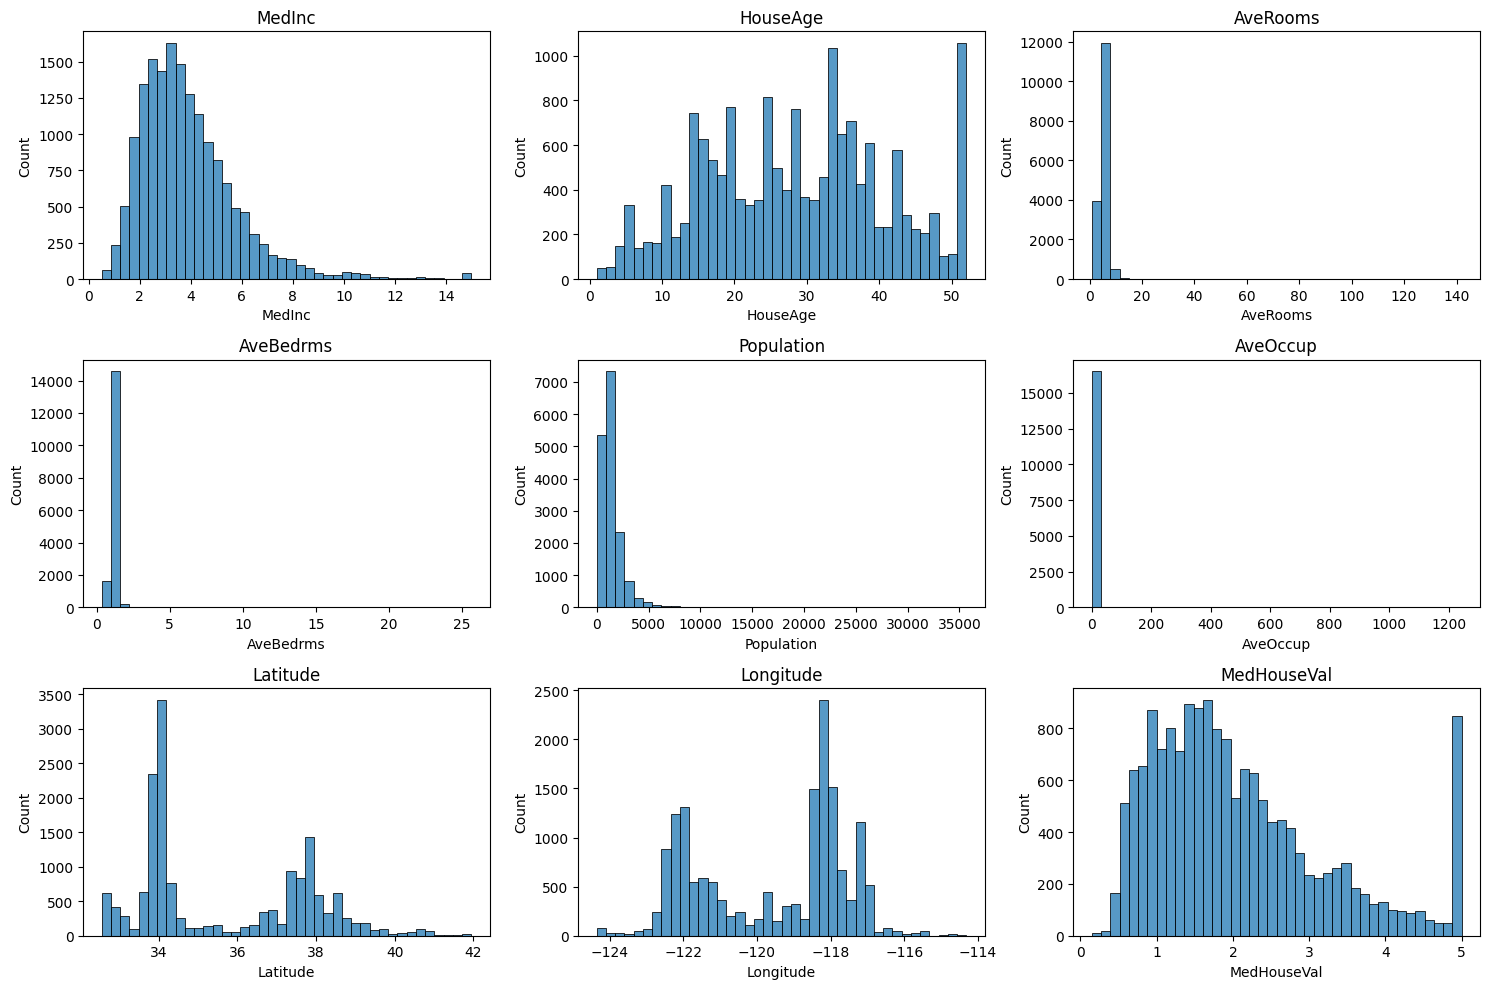

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), train_r.columns):
    sns.histplot(train_r[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

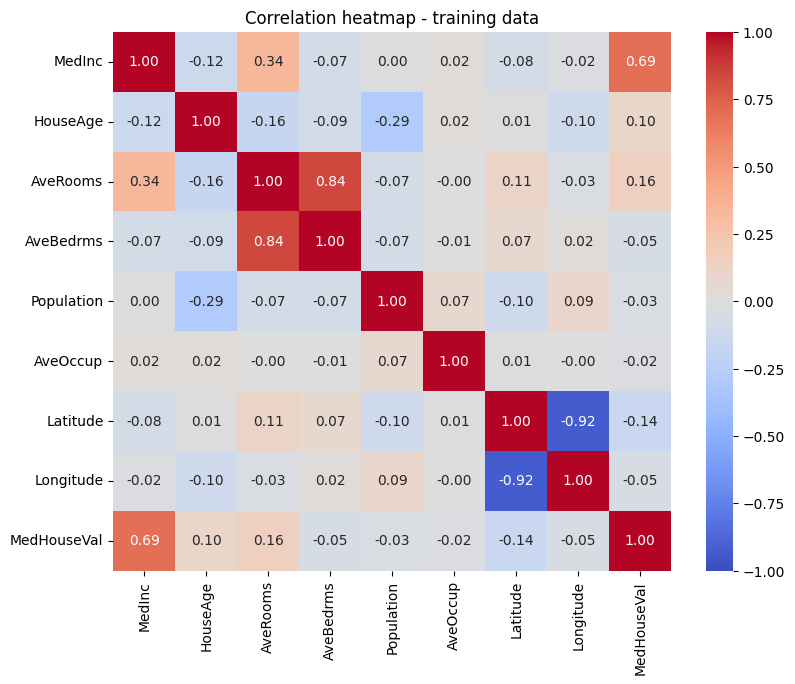

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(train_r.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap - training data")
plt.show()

In [8]:
print("Districts at the $500,000 cap (train):", (y_train_r >= 5.0).sum())

Districts at the $500,000 cap (train): 808


### Interpretation: Split and EDA
I split the data into 16,512 training rows (80%) and 4,128 test rows (20%), and explored the training data only.

- Target: MedHouseVal ranges from 0.15 to 5.00 ($15,000 to $500,000), with a median of 1.80 ($180,000). It is right-skewed, and 808 training districts sit exactly at 5.00, because values above $500,000 were capped. The models cannot learn the true value of these districts.
- MedInc (median income) is right-skewed (median 3.55, which means about $35,500, max 15.0) and is by far the strongest predictor of house value (correlation 0.69).
- AveRooms, AveBedrms, Population and AveOccup have extreme outliers (for example, AveOccup up to 1,243 people per household, compared with a median of 2.8). These are probably special places such as dorms or resorts.
- Latitude and longitude show two big peaks, around Los Angeles and the San Francisco Bay Area, so location matters.
- Multicollinearity: AveRooms and AveBedrms are highly correlated (0.84), and Latitude and Longitude are strongly negatively correlated (-0.92).

There are no missing values or categorical columns. I will keep the outliers, because tree-based models are robust to them, and I will scale the features only for Linear Regression, inside a pipeline.

### Step 4: Preprocessing and Model Implementation
The data has no missing values and no categorical features, so the only preprocessing needed is scaling for Linear Regression. I put the scaler inside a pipeline, so it is learned from the training data only (and from each training fold during cross-validation). Tree-based models do not need scaling.

In [9]:
reg_models = {
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=random_seed),
    "Random Forest": RandomForestRegressor(random_state=random_seed, n_jobs=-1),
    "XGBoost": XGBRegressor(random_state=random_seed, n_jobs=-1)
}

In [10]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=random_seed)
reg_cv_rows = []
for name, model in reg_models.items():
    cv = cross_validate(model, X_train_r, y_train_r, cv=cv_reg,
                        scoring=["neg_root_mean_squared_error", "r2"], return_train_score=True)
    reg_cv_rows.append({"Model": name,
                        "Train RMSE": -cv["train_neg_root_mean_squared_error"].mean(),
                        "CV RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
                        "CV R²": cv["test_r2"].mean()})
reg_cv_df = pd.DataFrame(reg_cv_rows).round(3)
reg_cv_df

,Model,Train RMSE,CV RMSE,CV R²
0,Linear Regression,0.720,0.721,0.611
1,Decision Tree,0.000,0.733,0.597
2,Random Forest,0.191,0.511,0.805
3,XGBoost,0.252,0.474,0.832


### Interpretation: Baseline Models (5-Fold Cross-Validation)
- XGBoost performed best, with a CV RMSE of 0.474 (about $47,400) and a CV R² of 0.832, followed by Random Forest (RMSE 0.511, R² 0.805).
- Linear Regression has almost the same training and CV RMSE (0.720 and 0.721), so it does not overfit, but it explains only 61% of the variation, because the relationships (for example, location) are not linear.
- The Decision Tree has a training RMSE of 0.000 but a CV RMSE of 0.733: it memorized the training data perfectly but performs worst on new data. This is extreme overfitting, caused by growing the tree without any depth limit.
- Random Forest and XGBoost also fit the training data much better than the CV data, but they still generalize far better than a single tree, because they combine many trees.
Next, I will tune the hyperparameters to reduce overfitting and improve performance.

### Step 5: Hyperparameter Tuning with GridSearchCV
I tune two models: the Decision Tree (to show how its hyperparameters control overfitting) and XGBoost (the best baseline model).

In [11]:
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=random_seed),
                       {"max_depth": [4, 6, 8, 10, 12, None], "min_samples_leaf": [1, 5, 20]},
                       scoring="neg_root_mean_squared_error", cv=cv_reg, n_jobs=-1, return_train_score=True)
dt_grid.fit(X_train_r, y_train_r)
print("Best Decision Tree:", dt_grid.best_params_, "| CV RMSE:", round(-dt_grid.best_score_, 3))

Best Decision Tree: {'max_depth': None, 'min_samples_leaf': 20} | CV RMSE: 0.616


In [12]:
dt_res = pd.DataFrame(dt_grid.cv_results_)
dt_res["Train RMSE"] = -dt_res["mean_train_score"]
dt_res["CV RMSE"] = -dt_res["mean_test_score"]
dt_res[dt_res["param_min_samples_leaf"] == 20][["param_max_depth", "Train RMSE", "CV RMSE"]].round(3)

,param_max_depth,Train RMSE,CV RMSE
2,4,0.739,0.757
5,6,0.657,0.690
8,8,0.586,0.644
11,10,0.537,0.623
14,12,0.515,0.616
17,None,0.509,0.616


In [13]:
xgb_grid = GridSearchCV(XGBRegressor(random_state=random_seed, n_jobs=-1),
                        {"n_estimators": [200, 400], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1]},
                        scoring="neg_root_mean_squared_error", cv=cv_reg, return_train_score=True)
xgb_grid.fit(X_train_r, y_train_r)
print("Best XGBoost:", xgb_grid.best_params_, "| CV RMSE:", round(-xgb_grid.best_score_, 3))

Best XGBoost: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 400} | CV RMSE: 0.46


In [14]:
xgb_res = pd.DataFrame(xgb_grid.cv_results_)
xgb_res["Train RMSE"] = -xgb_res["mean_train_score"]
xgb_res["CV RMSE"] = -xgb_res["mean_test_score"]
xgb_res.sort_values("CV RMSE")[["param_n_estimators", "param_max_depth", "param_learning_rate", "Train RMSE", "CV RMSE"]].head(6).round(3)

,param_n_estimators,param_max_depth,param_learning_rate,Train RMSE,CV RMSE
9,400,6,0.10,0.212,0.460
11,400,8,0.10,0.086,0.463
5,400,8,0.05,0.161,0.463
3,400,6,0.05,0.288,0.464
10,200,8,0.10,0.158,0.465
8,200,6,0.10,0.287,0.466


### Interpretation: Hyperparameter Tuning
Decision Tree:
The best tree uses min_samples_leaf = 20 with no depth limit, reducing the CV RMSE from 0.733 (default tree) to 0.616. The table shows the effect of max_depth: a shallow tree (depth 4) underfits (train RMSE 0.739, CV RMSE 0.757), and the CV RMSE improves as depth increases up to about 12. Beyond that there is no further gain, because requiring at least 20 districts per leaf already stops the tree from memorizing individual districts. This leaf limit is what removed the extreme overfitting I saw in the default tree (training RMSE 0.000).

XGBoost:
The best combination is 400 trees, max_depth 6 and learning_rate 0.1, with a CV RMSE of 0.460 (about $46,000), a small improvement on the default 0.474. Using more trees (400 instead of 200) helped in every case. Deeper trees (depth 8) fit the training data much more closely (training RMSE as low as 0.086) without improving the CV RMSE, which shows that extra depth mostly adds overfitting. The top six combinations are all within 0.006 of each other, so XGBoost is not very sensitive to these settings.

### Step 6: Model Evaluation on the Test Set

In [15]:
def reg_metrics(name, model):
    pred = model.predict(X_test_r)
    mse = mean_squared_error(y_test_r, pred)
    return {"Model": name, "MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_test_r, pred), "R²": r2_score(y_test_r, pred)}

In [16]:
reg_models["Linear Regression"].fit(X_train_r, y_train_r)
reg_models["Random Forest"].fit(X_train_r, y_train_r)
best_dt = dt_grid.best_estimator_
best_xgb = xgb_grid.best_estimator_

reg_test_df = pd.DataFrame([reg_metrics("Linear Regression", reg_models["Linear Regression"]),
                            reg_metrics("Decision Tree (tuned)", best_dt),
                            reg_metrics("Random Forest", reg_models["Random Forest"]),
                            reg_metrics("XGBoost (tuned)", best_xgb)]).round(3)
reg_test_df

,Model,MSE,RMSE,MAE,R²
0,Linear Regression,0.556,0.746,0.533,0.576
1,Decision Tree (tuned),0.357,0.598,0.404,0.727
2,Random Forest,0.255,0.505,0.328,0.805
3,XGBoost (tuned),0.199,0.447,0.291,0.848


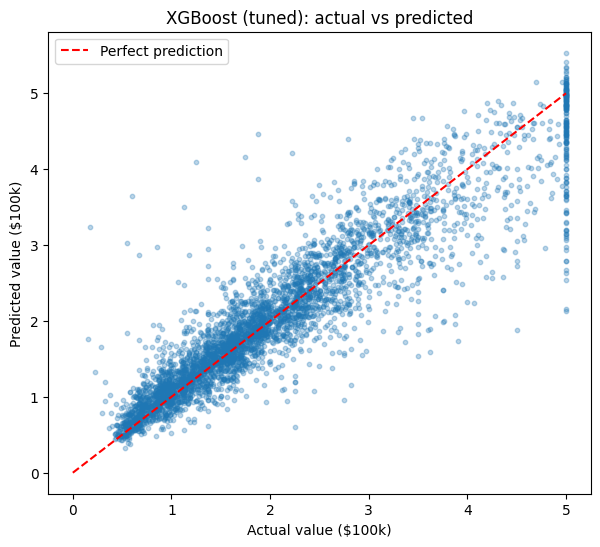

In [17]:
pred_xgb = best_xgb.predict(X_test_r)
plt.figure(figsize=(7, 6))
plt.scatter(y_test_r, pred_xgb, alpha=0.3, s=10)
plt.plot([0, 5], [0, 5], "r--", label="Perfect prediction")
plt.xlabel("Actual value ($100k)"); plt.ylabel("Predicted value ($100k)")
plt.title("XGBoost (tuned): actual vs predicted"); plt.legend()
plt.show()

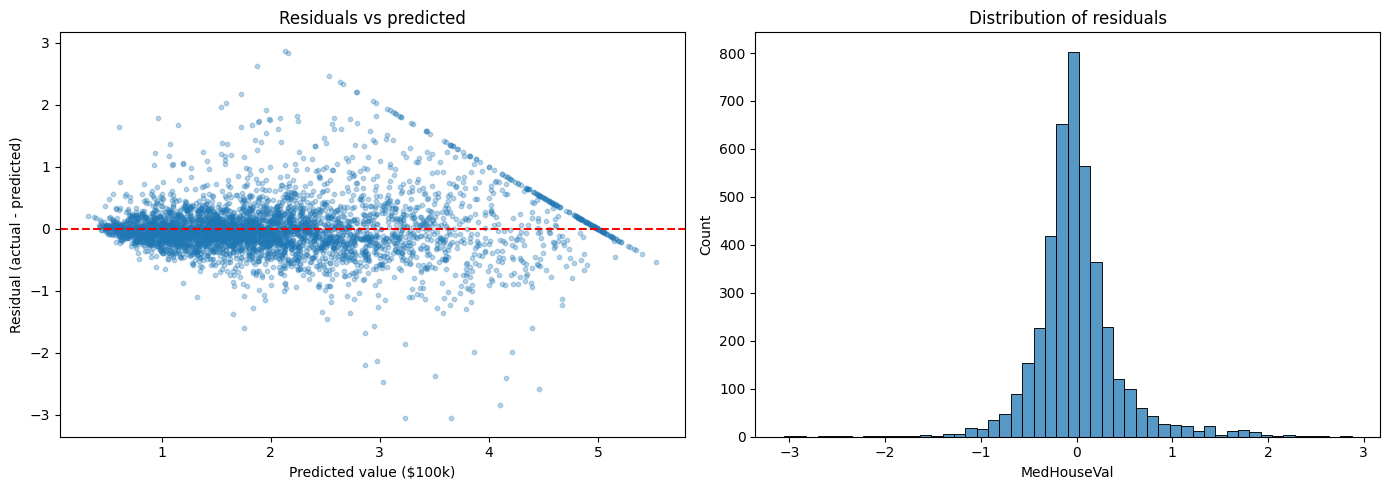

In [18]:
residuals = y_test_r - pred_xgb
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(pred_xgb, residuals, alpha=0.3, s=10)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted value ($100k)"); axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs predicted")
sns.histplot(residuals, bins=50, ax=axes[1])
axes[1].set_title("Distribution of residuals")
plt.tight_layout()
plt.show()

### Interpretation: Regression Test Results
Test set results (lower MSE, RMSE and MAE are better; higher R² is better):
- XGBoost (tuned): MSE 0.199, RMSE 0.447 (about $44,700), MAE 0.291 (about $29,100), R² 0.848
- Random Forest: RMSE 0.505, R² 0.805
- Decision Tree (tuned): RMSE 0.598, R² 0.727
- Linear Regression: RMSE 0.746, R² 0.576

The tuned XGBoost is the best model: it explains about 85% of the variation in house values, and its test RMSE (0.447) is close to its CV RMSE (0.460), so the cross-validation estimate was reliable. The ranking matches cross-validation: the ensemble models clearly beat a single tree and Linear Regression, because the relationships, especially with location, are not linear.

Actual vs predicted:
Most points lie close to the red diagonal, especially for low and medium house values. At an actual value of 5.0 there is a vertical stripe: these are the districts capped at $500,000, whose real values could be much higher. The model predicts anywhere from about 2 to 5.5 for them, which creates some of the largest errors.

Residuals:
The residuals are centred around 0 and roughly bell-shaped, so the model is not systematically over- or under-predicting. The spread of errors grows for more expensive districts. The straight diagonal line of points in the residual plot is caused by the $500,000 cap: for capped districts, the residual is simply 5.0 minus the prediction. Most errors are within plus or minus 0.5 ($50,000).

## Part 3: Classification – Titanic Survival
### Step 1: Load the Data

In [19]:
titanic = sns.load_dataset("titanic")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [20]:
print("Shape:", titanic.shape)
print("Duplicate rows:", titanic.duplicated().sum())
print("\nMissing values:\n", titanic.isnull().sum()[titanic.isnull().sum() > 0])
print("\nSurvival rate:\n", titanic["survived"].value_counts(normalize=True).round(3))

Shape: (891, 15)
Duplicate rows: 107

Missing values:
 age            177
embarked         2
deck           688
embark_town      2
dtype: int64

Survival rate:
 survived
0    0.616
1    0.384
Name: proportion, dtype: float64


### Interpretation: Titanic Data
The dataset has 891 passengers and 15 columns. The target is survived (1 = survived, 0 = died). 38.4% of passengers survived and 61.6% died, so the classes are moderately imbalanced. I will use a stratified split and look at precision, recall, F1-score and ROC AUC, not only accuracy.

Columns I will remove:
- alive is a yes/no copy of survived (the answer itself), so keeping it would be data leakage.
- class repeats pclass, and embark_town repeats embarked.
- who and adult_male are created from sex and age, and alone is created from sibsp and parch, so they repeat existing information.
- deck is missing for 688 passengers (77%), which is too much to fill reliably.

Missing values: age is missing for 177 passengers (20%) and embarked for 2. I will fill them inside the pipeline using values learned from the training data (the median for age, the most common value for embarked).

Duplicates: there are 107 duplicate rows, but this version of the dataset has no name or ticket columns, so different passengers with the same class, sex, age, fare and family size look identical. I will keep them as separate passengers.

In [21]:
titanic = titanic.drop(columns=["alive", "class", "embark_town", "who", "adult_male", "alone", "deck"])
print("Columns kept:", list(titanic.columns))

Columns kept: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


### Step 2: Split the Data into Training and Test Sets

In [22]:
X_clf = titanic.drop(columns="survived")
y_clf = titanic["survived"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2,
                                                            random_state=random_seed, stratify=y_clf)
print("Train:", X_train_c.shape, "| Test:", X_test_c.shape)
print("Survival rate - train:", round(y_train_c.mean(), 3), "| test:", round(y_test_c.mean(), 3))

Train: (712, 7) | Test: (179, 7)
Survival rate - train: 0.383 | test: 0.385


### Step 3: Exploratory Data Analysis (Training Data)

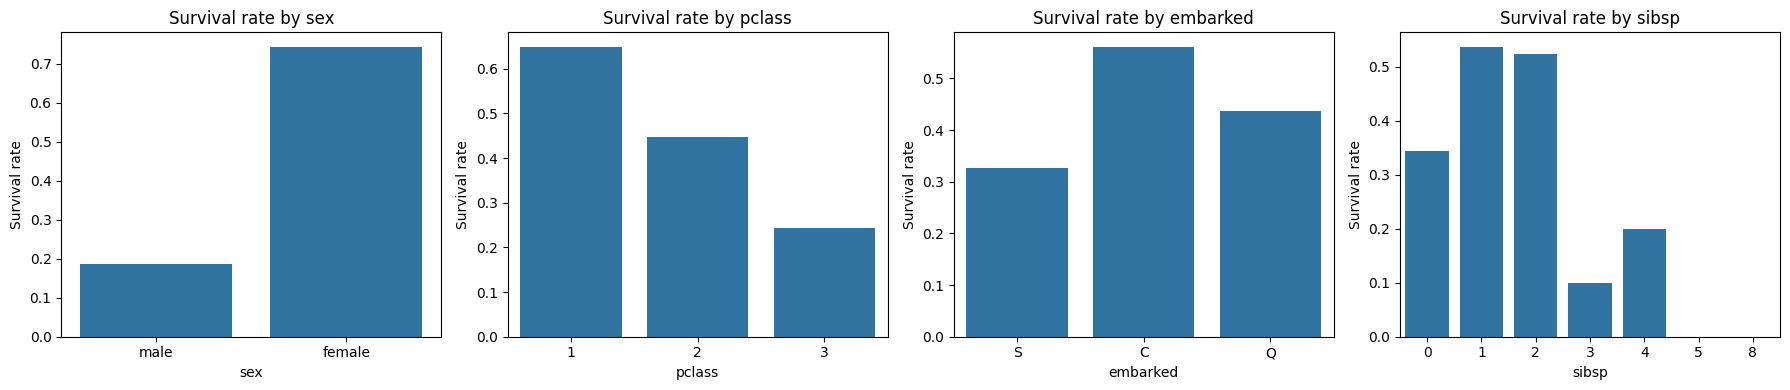

In [23]:
train_c = X_train_c.assign(survived=y_train_c)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["sex", "pclass", "embarked", "sibsp"]):
    sns.barplot(x=col, y="survived", data=train_c, ax=ax, errorbar=None)
    ax.set_title(f"Survival rate by {col}"); ax.set_ylabel("Survival rate")
plt.tight_layout()
plt.show()

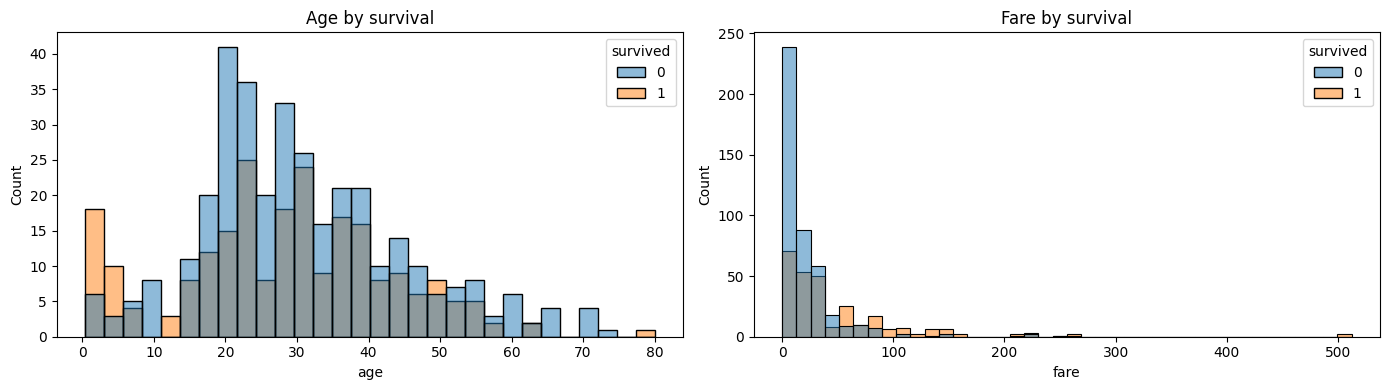

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=train_c, x="age", hue="survived", bins=30, ax=axes[0])
sns.histplot(data=train_c, x="fare", hue="survived", bins=40, ax=axes[1])
axes[0].set_title("Age by survival"); axes[1].set_title("Fare by survival")
plt.tight_layout()
plt.show()

In [27]:
print("Missing values (train):\n", X_train_c.isnull().sum()[X_train_c.isnull().sum() > 0])
train_c[["age", "fare", "sibsp", "parch"]].describe().T.round(2)


Missing values (train):
 age         137
embarked      2
dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,575.0,29.81,14.49,0.42,21.0,28.50,39.0,80.00
fare,712.0,31.82,48.06,0.00,7.9,14.45,31.0,512.33
sibsp,712.0,0.49,1.06,0.00,0.0,0.00,1.0,8.00
parch,712.0,0.39,0.84,0.00,0.0,0.00,0.0,6.00


### Interpretation: Titanic EDA (Training Data)
After removing the leakage and redundant columns, I kept 7 features (pclass, sex, age, sibsp, parch, fare and embarked) and split the data into 712 training and 179 test passengers, keeping the 38% survival rate in both sets.

- Sex is the strongest pattern: about 74% of women survived compared with about 19% of men, which reflects the "women and children first" rule.
- Passenger class matters: about 63% of 1st class passengers survived, compared with about 47% in 2nd class and only about 24% in 3rd class.
- Passengers who embarked at Cherbourg survived more often (about 56%) than those from Southampton (about 33%), probably because more of them travelled in 1st class.
- Passengers with 1 or 2 siblings or spouses on board survived more often (about 53%) than passengers travelling alone (about 34%), while large families (3 or more) had very low survival.
- Young children (under about 10) mostly survived, while many passengers aged 20 to 30 died.
- Fare is very right-skewed (median 14.45, maximum 512.33), and passengers who paid higher fares survived more often, which is linked to class.

Missing values in the training data: age (137) and embarked (2). I will fill them in the preprocessing pipeline.

### Step 4: Preprocessing Pipeline
I use a ColumnTransformer so each column type gets the right preprocessing, learned from the training data only:
- Numeric features (age, sibsp, parch, fare): fill missing values with the median, then scale with StandardScaler.
- Categorical features (sex, embarked, pclass): fill missing values with the most frequent value, then one-hot encode.

In [28]:
num_features = ["age", "sibsp", "parch", "fare"]
cat_features = ["sex", "embarked", "pclass"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))]), cat_features)
])

In [33]:
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=random_seed),
    "Random Forest": RandomForestClassifier(random_state=random_seed, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=random_seed, n_jobs=-1, eval_metric="logloss"),
    "SVM": SVC(probability=True, random_state=random_seed)
}
clf_pipes = {name: Pipeline([("prep", preprocessor), ("model", m)]) for name, m in clf_models.items()}

In [34]:
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)
clf_cv_rows = []
for name, pipe in clf_pipes.items():
    cv = cross_validate(pipe, X_train_c, y_train_c, cv=cv_clf,
                        scoring=["accuracy", "f1", "roc_auc"], return_train_score=True)
    clf_cv_rows.append({"Model": name, "Train acc": cv["train_accuracy"].mean(),
                        "CV acc": cv["test_accuracy"].mean(), "CV F1": cv["test_f1"].mean(),
                        "CV ROC AUC": cv["test_roc_auc"].mean()})
clf_cv_df = pd.DataFrame(clf_cv_rows).round(3)
clf_cv_df

,Model,Train acc,CV acc,CV F1,CV ROC AUC
0,Logistic Regression,0.808,0.802,0.729,0.853
1,Decision Tree,0.982,0.771,0.699,0.760
2,Random Forest,0.982,0.809,0.743,0.864
3,XGBoost,0.975,0.806,0.743,0.870
4,SVM,0.841,0.816,0.746,0.848


### Interpretation: Baseline Classification Models (5-Fold Stratified Cross-Validation)
- All five models perform fairly similarly, with CV accuracy between 77% and 82%.
- SVM has the best CV accuracy (0.816) and F1-score (0.746), while XGBoost has the highest ROC AUC (0.870), followed by Random Forest (0.864).
- Logistic Regression is a strong simple baseline (accuracy 0.802, ROC AUC 0.853) with almost no overfitting (training 0.808 compared with CV 0.802).
- The Decision Tree, Random Forest and XGBoost reach 97 to 98% training accuracy but only 77 to 81% CV accuracy, so their default settings overfit: they memorize individual passengers. The single Decision Tree overfits the most and has the lowest CV performance (accuracy 0.771, ROC AUC 0.760).
Next, I will tune Random Forest and SVM to reduce overfitting and improve their scores.

In [35]:
rf_grid = GridSearchCV(clf_pipes["Random Forest"],
                       {"model__n_estimators": [200, 400], "model__max_depth": [4, 6, 8, None],
                        "model__min_samples_leaf": [1, 3, 5]},
                       scoring="f1", cv=cv_clf, n_jobs=-1, return_train_score=True)
rf_grid.fit(X_train_c, y_train_c)

print("Best Random Forest:", rf_grid.best_params_, "| CV F1:", round(rf_grid.best_score_, 3))

Best Random Forest: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 400} | CV F1: 0.752


In [36]:
rf_res = pd.DataFrame(rf_grid.cv_results_)
rf_res.sort_values("rank_test_score")[["param_model__n_estimators", "param_model__max_depth",
        "param_model__min_samples_leaf", "mean_train_score", "mean_test_score"]].head(6).round(3)

,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score
21,400,None,3,0.861,0.752
20,200,None,3,0.859,0.749
13,400,8,1,0.899,0.749
3,400,4,3,0.780,0.747
12,200,8,1,0.895,0.746
4,200,4,5,0.780,0.744


In [37]:
svm_grid = GridSearchCV(clf_pipes["SVM"],
                        {"model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1, 1]},
                        scoring="f1", cv=cv_clf, n_jobs=-1, return_train_score=True)
svm_grid.fit(X_train_c, y_train_c)
print("Best SVM:", svm_grid.best_params_, "| CV F1:", round(svm_grid.best_score_, 3))

Best SVM: {'model__C': 100, 'model__gamma': 0.01} | CV F1: 0.756


In [38]:
svm_res = pd.DataFrame(svm_grid.cv_results_)
svm_res.pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score").round(3)

param_model__gamma,0.01,0.1,1,scale
param_model__C,,,,
0.1,0.007,0.679,0.474,0.717
1.0,0.722,0.750,0.734,0.746
10.0,0.719,0.752,0.717,0.734
100.0,0.756,0.720,0.706,0.719


### Interpretation: Hyperparameter Tuning (Classification)
Random Forest:
The best combination is 400 trees, no depth limit and min_samples_leaf = 3, with a CV F1-score of 0.752 (up from 0.743). Requiring at least 3 passengers per leaf reduced overfitting: training F1 dropped to 0.861, compared with near-perfect training scores for the default model. Shallow trees (max_depth 4) overfit the least (training F1 0.780) and still reached a CV F1 of 0.747, so limiting tree complexity costs very little performance. The top combinations are all within 0.008 of each other.

SVM:
The best combination is C = 100 and gamma = 0.01, with a CV F1-score of 0.756 (up from 0.746). The C and gamma table shows how the two settings work together:
- With a very small C (0.1) and a small gamma (0.01), the F1-score collapses to 0.007, because the model is so simple that it predicts almost no survivors (underfitting).
- A large gamma (1) gives lower scores for every C, because the decision boundary becomes too wiggly and fits noise.
- The best results come from balancing the two: a large C with a small gamma (0.756), or C between 1 and 10 with gamma 0.1 (0.750 to 0.752).
Tuning gave only small improvements, which suggests the default models were already close to the best this small dataset allows.

### Step 6: Model Evaluation on the Test Set

In [39]:
def clf_metrics(name, model):
    pred = model.predict(X_test_c)
    prob = model.predict_proba(X_test_c)[:, 1]
    return {"Model": name, "Accuracy": accuracy_score(y_test_c, pred), "Precision": precision_score(y_test_c, pred),
            "Recall": recall_score(y_test_c, pred), "F1": f1_score(y_test_c, pred), "ROC AUC": roc_auc_score(y_test_c, prob)}

In [40]:
for name in ["Logistic Regression", "Decision Tree", "XGBoost"]:
    clf_pipes[name].fit(X_train_c, y_train_c)
final_clf = {"Logistic Regression": clf_pipes["Logistic Regression"],
             "Decision Tree": clf_pipes["Decision Tree"],
             "Random Forest (tuned)": rf_grid.best_estimator_,
             "XGBoost": clf_pipes["XGBoost"],
             "SVM (tuned)": svm_grid.best_estimator_}
clf_test_df = pd.DataFrame([clf_metrics(n, m) for n, m in final_clf.items()]).round(3)
clf_test_df

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.799,0.780,0.667,0.719,0.844
1,Decision Tree,0.799,0.746,0.725,0.735,0.780
2,Random Forest (tuned),0.810,0.797,0.681,0.734,0.840
3,XGBoost,0.816,0.765,0.754,0.759,0.817
4,SVM (tuned),0.827,0.817,0.710,0.760,0.850


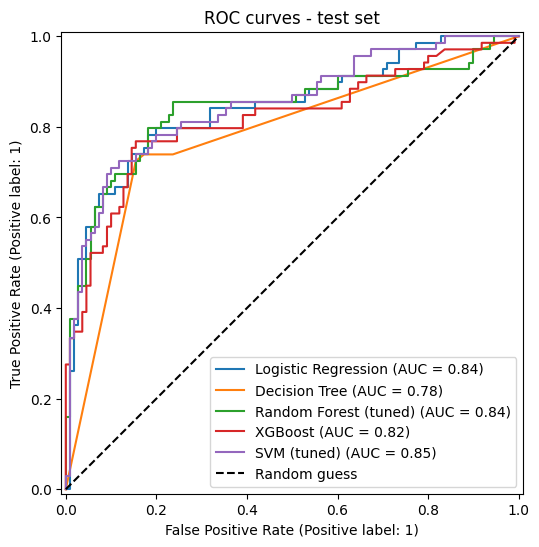

In [41]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in final_clf.items():
    RocCurveDisplay.from_estimator(model, X_test_c, y_test_c, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves - test set"); ax.legend()
plt.show()

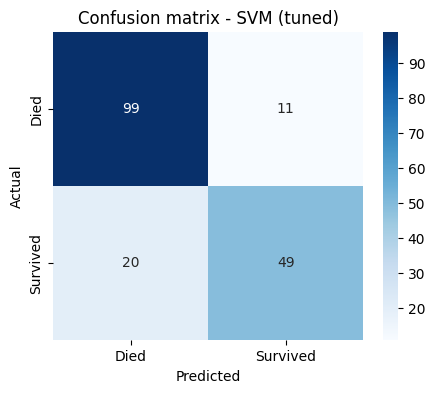

              precision    recall  f1-score   support

        Died       0.83      0.90      0.86       110
    Survived       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



In [42]:
best_clf = svm_grid.best_estimator_
pred_best = best_clf.predict(X_test_c)
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test_c, pred_best), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix - SVM (tuned)")
plt.show()
print(classification_report(y_test_c, pred_best, target_names=["Died", "Survived"]))

### Interpretation: Classification Test Results
Test set results:
- SVM (tuned): accuracy 0.827, precision 0.817, recall 0.710, F1 0.760, ROC AUC 0.850
- XGBoost: accuracy 0.816, recall 0.754 (highest), F1 0.759, ROC AUC 0.817
- Random Forest (tuned): accuracy 0.810, F1 0.734, ROC AUC 0.840
- Logistic Regression: accuracy 0.799, F1 0.719, ROC AUC 0.844
- Decision Tree: accuracy 0.799, F1 0.735, ROC AUC 0.780

The tuned SVM is the best model overall, with the highest accuracy, precision, F1-score and ROC AUC, which matches its top cross-validation F1-score. XGBoost finds the most survivors (highest recall), but with slightly lower precision. The differences between the models are small, because the test set has only 179 passengers.

ROC curves:
All models are well above the random-guess line. SVM, Logistic Regression and Random Forest have the best curves (AUC 0.84 to 0.85). The Decision Tree's curve has only a few corners and the lowest AUC (0.78), because a single tree gives only a few different probability values.

Confusion matrix (SVM):
- 99 of the 110 passengers who died were correctly predicted (recall 0.90), with only 11 wrongly predicted as survivors.
- 49 of the 69 survivors were correctly identified (recall 0.71), and 20 survivors were predicted as died.
The model is better at recognizing passengers who died than survivors. Most of its mistakes are probably survivors who do not fit the typical pattern (for example, men or 3rd class passengers who survived).

## Part 4: Conclusion

### Regression – California Housing
I compared Linear Regression, Decision Tree, Random Forest and XGBoost using 5-fold cross-validation, tuned the Decision Tree and XGBoost with GridSearchCV, and evaluated all models on the test set. The tuned XGBoost was the best model, with an R² of 0.848, an RMSE of 0.447 (about $44,700) and an MAE of 0.291 (about $29,100). Median income was the strongest predictor. Linear Regression was limited (R² 0.576) because the relationships, especially with location, are not linear. The default Decision Tree overfitted completely (training RMSE 0.000), and setting min_samples_leaf to 20 was the key fix. The residuals were centred around 0, but the $500,000 cap on house values caused the largest errors.

### Classification – Titanic
After removing a leakage column (alive) and redundant columns, I built a preprocessing pipeline that fills missing values, one-hot encodes the categories and scales the numeric features, all learned from the training data only. I compared Logistic Regression, Decision Tree, Random Forest, XGBoost and SVM, and tuned Random Forest and SVM. The tuned SVM (C = 100, gamma = 0.01) was the best model, with 82.7% accuracy, an F1-score of 0.760 and a ROC AUC of 0.850. Sex and passenger class were the strongest patterns in the data.

### Key lessons
- Splitting the data before exploring it, and keeping all preprocessing inside pipelines, prevents data leakage.
- Cross-validation gave reliable estimates: the test results matched the CV results for the best models.
- Ensemble and kernel models (XGBoost, Random Forest and SVM) performed better than single, simpler models.
- Hyperparameters that limit model complexity (min_samples_leaf, max_depth, C and gamma) were the most important for controlling overfitting.
- Choosing the right metrics matters: RMSE, MAE and R² for regression, and precision, recall, F1-score and ROC AUC for classification with imbalanced classes.